In [1]:
import pandas as pd
import numpy as np

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
dataset=pd.read_csv("diabetes_prediction_dataset.csv")

In [4]:
dataset.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [5]:
dataset = dataset.drop('gender', axis=1, errors='ignore')

In [6]:
dataset = pd.get_dummies(dataset, drop_first=True, dtype=int)


In [7]:
dataset.describe().T


,count,mean,std,min,25%,50%,75%,max
age,100000.0,41.885856,22.516840,0.08,24.00,43.00,60.00,80.00
hypertension,100000.0,0.074850,0.263150,0.00,0.00,0.00,0.00,1.00
heart_disease,100000.0,0.039420,0.194593,0.00,0.00,0.00,0.00,1.00
bmi,100000.0,27.320767,6.636783,10.01,23.63,27.32,29.58,95.69
HbA1c_level,100000.0,5.527507,1.070672,3.50,4.80,5.80,6.20,9.00
blood_glucose_level,100000.0,138.058060,40.708136,80.00,100.00,140.00,159.00,300.00
diabetes,100000.0,0.085000,0.278883,0.00,0.00,0.00,0.00,1.00
smoking_history_current,100000.0,0.092860,0.290238,0.00,0.00,0.00,0.00,1.00
smoking_history_ever,100000.0,0.040040,0.196054,0.00,0.00,0.00,0.00,1.00
smoking_history_former,100000.0,0.093520,0.291161,0.00,0.00,0.00,0.00,1.00


In [8]:
features=["blood_glucose_level", "hypertension", "heart_disease", "bmi", "HbA1c_level"]

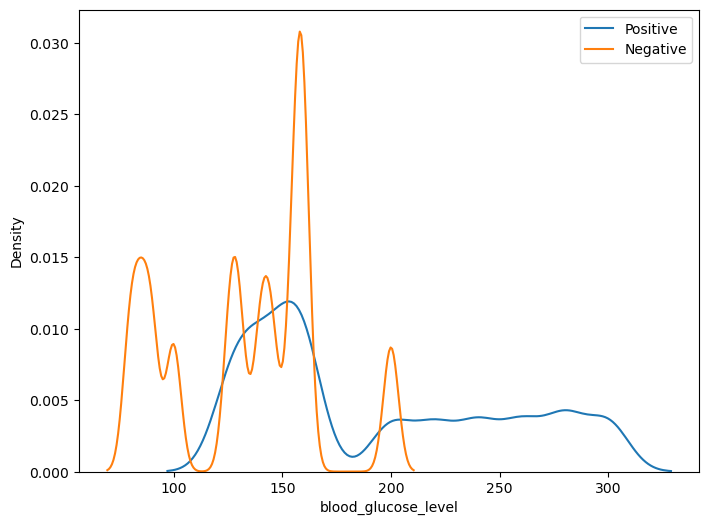

In [9]:
plt.figure(figsize=(8,6))
sns.kdeplot(data=dataset["blood_glucose_level"][dataset["diabetes"]==1])
sns.kdeplot(data=dataset["blood_glucose_level"][dataset["diabetes"]==0])
plt.legend(["Positive", "Negative"])
plt.show()

In [10]:
x=dataset.drop("diabetes", axis=1)

y=dataset["diabetes"]

In [11]:
from sklearn.model_selection import train_test_split

In [12]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

In [14]:
lr = LogisticRegression(max_iter=1000, class_weight='balanced')

lr.fit(x_train, y_train)
y_pred=lr.predict(x_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\n-----", classification_report(y_test, y_pred), "-----\n")

plt.figure(figsize=(3,3))
sns.heatmap(confusion_matrix(y_test, y_pred, annot= True, fmt="d", cmap="GnBu"))
plt.show()

Accuracy: 0.89005

-----               precision    recall  f1-score   support

           0       0.99      0.89      0.94     18300
           1       0.43      0.89      0.58      1700

    accuracy                           0.89     20000
   macro avg       0.71      0.89      0.76     20000
weighted avg       0.94      0.89      0.91     20000
 -----



TypeError: got an unexpected keyword argument 'annot'

<Figure size 300x300 with 0 Axes>

In [15]:
def run_model(model, x_train=x_train, x_test=x_test, y_train=y_train, y_test=y_test):
    model.fit(x_train, y_train)
    y_pred=model.predict(x_test)
    print("Acc: ", accuracy_score(y_test, y_pred))
    print("\n-----", classification_report(y_test, y_pred), "-----\n")
    plt.figure(figsize=(3,3))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot= True, fmt="d", cmap="GnBu")
    plt.show()
    return accuracy_score(y_test, y_pred)

Acc:  0.89005

-----               precision    recall  f1-score   support

           0       0.99      0.89      0.94     18300
           1       0.43      0.89      0.58      1700

    accuracy                           0.89     20000
   macro avg       0.71      0.89      0.76     20000
weighted avg       0.94      0.89      0.91     20000
 -----



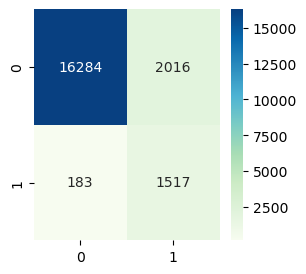

0.89005

In [16]:
run_model(lr)

In [17]:
from sklearn.neighbors import KNeighborsClassifier



====== 1 Neighbors ======
Acc:  0.9418

-----               precision    recall  f1-score   support

           0       0.97      0.97      0.97     18300
           1       0.67      0.62      0.65      1700

    accuracy                           0.94     20000
   macro avg       0.82      0.80      0.81     20000
weighted avg       0.94      0.94      0.94     20000
 -----



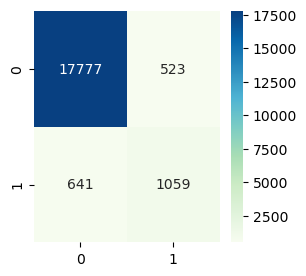



====== 2 Neighbors ======
Acc:  0.9537

-----               precision    recall  f1-score   support

           0       0.96      0.99      0.98     18300
           1       0.89      0.52      0.66      1700

    accuracy                           0.95     20000
   macro avg       0.92      0.76      0.82     20000
weighted avg       0.95      0.95      0.95     20000
 -----



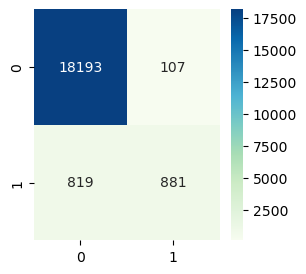



====== 3 Neighbors ======
Acc:  0.952

-----               precision    recall  f1-score   support

           0       0.96      0.99      0.97     18300
           1       0.80      0.58      0.67      1700

    accuracy                           0.95     20000
   macro avg       0.88      0.78      0.82     20000
weighted avg       0.95      0.95      0.95     20000
 -----



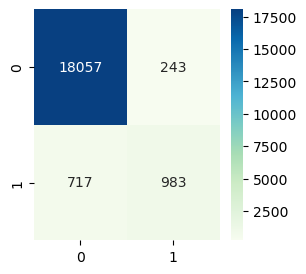



====== 4 Neighbors ======
Acc:  0.9553

-----               precision    recall  f1-score   support

           0       0.96      1.00      0.98     18300
           1       0.93      0.51      0.66      1700

    accuracy                           0.96     20000
   macro avg       0.94      0.75      0.82     20000
weighted avg       0.95      0.96      0.95     20000
 -----



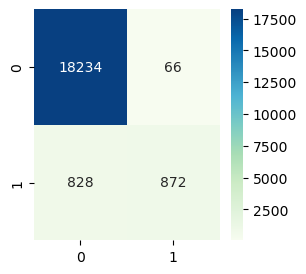



====== 5 Neighbors ======
Acc:  0.9553

-----               precision    recall  f1-score   support

           0       0.96      0.99      0.98     18300
           1       0.88      0.55      0.68      1700

    accuracy                           0.96     20000
   macro avg       0.92      0.77      0.83     20000
weighted avg       0.95      0.96      0.95     20000
 -----



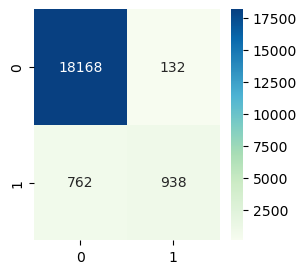



====== 6 Neighbors ======
Acc:  0.95525

-----               precision    recall  f1-score   support

           0       0.96      1.00      0.98     18300
           1       0.94      0.51      0.66      1700

    accuracy                           0.96     20000
   macro avg       0.95      0.75      0.82     20000
weighted avg       0.95      0.96      0.95     20000
 -----



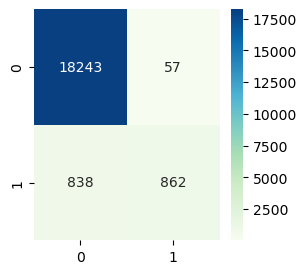



====== 7 Neighbors ======
Acc:  0.9558

-----               precision    recall  f1-score   support

           0       0.96      1.00      0.98     18300
           1       0.91      0.53      0.67      1700

    accuracy                           0.96     20000
   macro avg       0.93      0.76      0.82     20000
weighted avg       0.95      0.96      0.95     20000
 -----



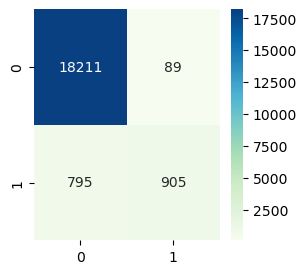

0.9558


In [18]:
acc_knn=[]
for n in range(1,8):
    knn=KNeighborsClassifier(n_neighbors=n)
    print(f"\n\n====== {n} Neighbors ======")
    acc_knn.append(run_model(knn))

print(max(acc_knn))

In [19]:
max(acc_knn), acc_knn.index(max(acc_knn))

(0.9558, 6)

In [20]:
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

In [21]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [22]:
print(x_train.shape)
print(y_train.shape)
print(x_train_scaled.shape)
print(x_test_scaled.shape)

(80000, 11)
(80000,)
(80000, 11)
(20000, 11)


In [23]:

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=18,
    min_samples_split=5,
    min_samples_leaf=3,
    max_features='sqrt',
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)


In [24]:
rf.fit(x_train_scaled, y_train)
y_pred_rf = rf.predict(x_test_scaled)

Random Forest Accuracy: 0.94775

----- RF Classification Report -----
               precision    recall  f1-score   support

           0       0.98      0.96      0.97     18300
           1       0.66      0.81      0.72      1700

    accuracy                           0.95     20000
   macro avg       0.82      0.89      0.85     20000
weighted avg       0.95      0.95      0.95     20000



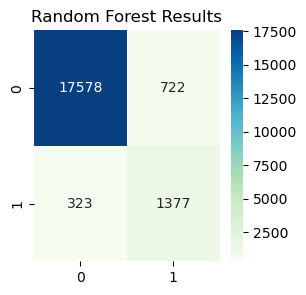

In [25]:
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print("\n----- RF Classification Report -----\n", classification_report(y_test, y_pred_rf))

plt.figure(figsize=(3,3))
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt="d", cmap="GnBu")
plt.title("Random Forest Results")
plt.show()

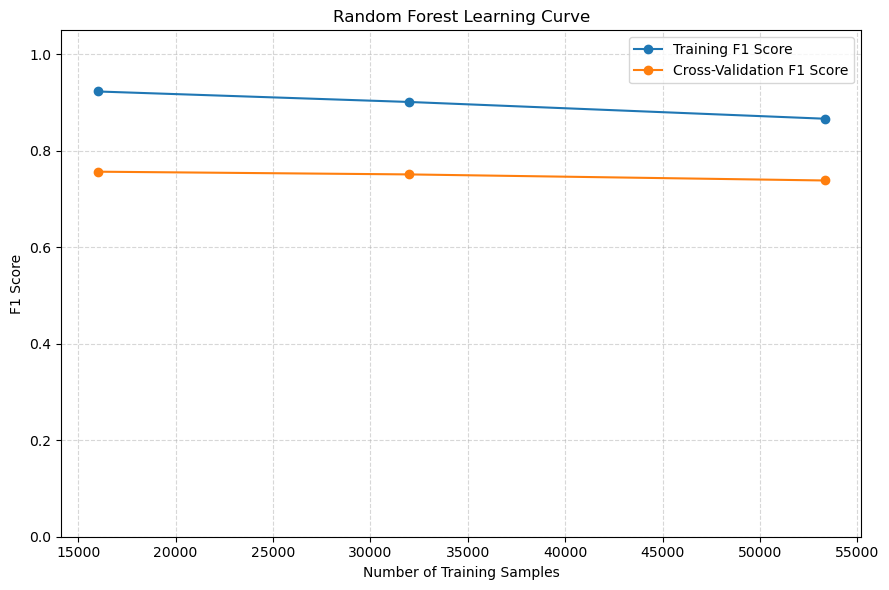

In [26]:
from sklearn.model_selection import learning_curve, StratifiedKFold

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

train_sizes, train_scores, val_scores = learning_curve(
    estimator=rf,
    X=x_train_scaled,
    y=y_train,
    train_sizes=[0.3, 0.6, 1.0],
    cv=cv,
    scoring='f1',
    n_jobs=1
)

train_mean = np.mean(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)

plt.figure(figsize=(9, 6))

plt.plot(
    train_sizes,
    train_mean,
    marker='o',
    label='Training F1 Score'
)

plt.plot(
    train_sizes,
    val_mean,
    marker='o',
    label='Cross-Validation F1 Score'
)

plt.title('Random Forest Learning Curve')
plt.xlabel('Number of Training Samples')
plt.ylabel('F1 Score')

plt.ylim(0, 1.05)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()
